# Экзаменационная задача №09. Выбор модели для AI-сервиса поддержки (затраты на токены)

**Дисциплина:** Экономика информатизации, лекция №10
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №09: ВЫБОР МОДЕЛИ ДЛЯ AI-СЕРВИСА ПОДДЕРЖКИ (ЗАТРАТЫ НА ТОКЕНЫ)
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №10)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Компания «ГосТех» запускает AI-чат поддержки граждан. Затраты сильно зависят от того, как его построить.
У API-провайдера платим за токены, то есть затраты почти полностью **переменные**. Свой сервер с open-source моделью
даёт почти только **постоянные** затраты (GPU, персонал). Гибрид с кешированием уменьшает переменную часть.
Объём запросов растёт, поэтому выбор зависит от того, где проходит точка безубыточности.

**Цель:** выбрать самую дешёвую схему на 3 года и найти объём, при котором выгоднее свой сервер.

Тема лекции №10: экономика работы моделей, стоимость токенов, open-source против API, TCO вычислительных ресурсов.

## 2. Исходные данные

In [2]:
# 1.1. Параметры сервиса
monthly_requests = {1: 50_000, 2: 200_000, 3: 500_000}   # запросов в месяц по годам
tok_in, tok_out = 300, 150                               # токенов на запрос
r = 0.12; H = 3
# 1.2. Вариант 1 — API (GPT-4 Turbo)
p_in, p_out, price_growth, api_integration = 0.01, 0.03, 0.05, 5_000      # $ за 1K токенов; $ разово
# 1.3. Вариант 2 — self-host (Llama 3 + fine-tune)
sh_capex = {"Оборудование 4×A100": 40_000, "Fine-tuning": 5_000, "Интеграция": 8_000}
sh_opex = {"Эксплуатация": 3_000, "DevOps (частично)": 10_000, "Электричество и охлаждение": 2_000}
# 1.4. Вариант 3 — гибрид (API + кеш)
cache_share, cache_cost = 0.40, 2_000
cost_per_request = tok_in / 1000 * p_in + tok_out / 1000 * p_out
print(f"Стоимость запроса через API в 1-й год: {tok_in}/1000·{p_in} + {tok_out}/1000·{p_out} = ${cost_per_request:.4f}")

Стоимость запроса через API в 1-й год: 300/1000·0.01 + 150/1000·0.03 = $0.0075


**Допущения:**
- Объём в условии дан **в месяц**, поэтому за год умножаем на 12 (0,6 / 2,4 / 6 млн запросов в год).
  Для сравнения отдельно показан расчёт, если считать эти объёмы годовыми.
- Разовые затраты (интеграция, оборудование, дообучение) в момент t = 0, текущие в конце каждого года.
- Гибриду тоже нужна интеграция с API (5 000 $), как варианту 1. Цены API растут на 5 % в год со 2-го года.
- 4×A100 с большим запасом хватает на 500 тыс. запросов в месяц (в среднем около 0,2 запроса в секунду).

## 3. Математическая модель

$$c_t = \Big(\tfrac{300}{1000}\cdot0{,}01+\tfrac{150}{1000}\cdot0{,}03\Big)(1{,}05)^{t-1},\qquad
C^{API}_t = 12\,Q_t\,c_t,\qquad C^{гибр}_t = 0{,}6\cdot12\,Q_t\,c_t + 2000$$
$$C^{self}_t = OPEX = 15\,000\ \$,\qquad PV = C_0+\sum_{t=1}^{3}\frac{C_t}{1{,}12^t}$$
Точка безубыточности: такой объём $Q^*$ (во сколько раз больше плана), при котором $PV^{API}(Q^*) = PV^{self}$.

## 4. Реализация расчёта
### 4.1. Годовые затраты и TCO

In [3]:
def costs(volume_mult=1.0, price_mult=1.0, annual_volumes=False):
    """Таблица затрат по годам ($) для трёх вариантов."""
    rows = []
    for t in range(H + 1):
        q = 0 if t == 0 else monthly_requests[t] * volume_mult * (1 if annual_volumes else 12)
        c = cost_per_request * price_mult * (1 + price_growth) ** (t - 1) if t else 0
        rows.append({"Год": t, "Запросов в год": q, "Цена запроса, $": c,
                     "API": api_integration if t == 0 else q * c,
                     "Self-host": sum(sh_capex.values()) if t == 0 else sum(sh_opex.values()),
                     "Гибрид": api_integration if t == 0 else q * (1 - cache_share) * c + cache_cost})
    return pd.DataFrame(rows).set_index("Год")

C = costs()
display(C.assign(**{"Цена запроса, $": C["Цена запроса, $"].map(lambda v: f"{v:.6f}")}).round(0))
variants = ["API", "Self-host", "Гибрид"]
summary = pd.DataFrame({"TCO номинал, $": C[variants].sum(), "TCO дисконт. (12%), $": [npv(C[v].values, r) for v in variants]})
summary["Ранг"] = summary["TCO дисконт. (12%), $"].rank().astype(int)
summary.round(0)

,Запросов в год,"Цена запроса, $",API,Self-host,Гибрид
Год,,,,,
0,0.00,0.000000,5 000.00,53000,5 000.00
1,600 000.00,0.007500,4 500.00,15000,4 700.00
2,2 400 000.00,0.007875,18 900.00,15000,13 340.00
3,6 000 000.00,0.008269,49 612.00,15000,31 768.00


,"TCO номинал, $","TCO дисконт. (12%), $",Ранг
API,78 012.00,59 398.00,2
Self-host,98 000.00,89 027.00,3
Гибрид,54 808.00,42 442.00,1


### 4.2. Точка безубыточности: API против своего сервера

In [4]:
from utils.calculations import solve_for
pv = lambda v, **kw: npv(costs(**kw)[v].values, r)
m_api = solve_for(lambda m: pv("API", volume_mult=m) - pv("Self-host", volume_mult=m), 0, 0.01, 50)
m_hyb = solve_for(lambda m: pv("Гибрид", volume_mult=m) - pv("Self-host", volume_mult=m), 0, 0.01, 50)
print(f"API = self-host при множителе нагрузки {m_api:.2f} "
      f"(≈{m_api*50_000:,.0f} → {m_api*200_000:,.0f} → {m_api*500_000:,.0f} запросов/мес.)".replace(",", " "))
print(f"Гибрид = self-host при множителе {m_hyb:.2f} (≈{m_hyb*500_000:,.0f} запросов/мес. в 3-й год)".replace(",", " "))
# Постоянная нагрузка: при каком объёме в месяц годовые операционные затраты равны
q_star = sum(sh_opex.values()) / (12 * cost_per_request)
print(f"Операционная безубыточность (без учёта CAPEX): {q_star:,.0f} запросов/мес. — выше этого self-host дешевле в текущих затратах".replace(",", " "))
# Год, в котором накопленные PV-затраты API превышают self-host
cum = pd.DataFrame({v: np.cumsum(present_values(C[v].values, r)) for v in variants}, index=C.index)
cum

API = self-host при множителе нагрузки 1.54 (≈77 234 → 308 936 → 772 339 запросов/мес.)
Гибрид = self-host при множителе 2.43 (≈1 213 644 запросов/мес. в 3-й год)
Операционная безубыточность (без учёта CAPEX): 166 667 запросов/мес. — выше этого self-host дешевле в текущих затратах


,API,Self-host,Гибрид
Год,,,
0,5 000.00,53 000.00,5 000.00
1,9 017.86,66 392.86,9 196.43
2,24 084.82,78 350.77,19 830.99
3,59 398.02,89 027.47,42 442.47


### 4.3. Анализ чувствительности

In [5]:
rows = []
for k in [0.7, 1.0, 1.3]:
    rows.append({"Фактор": "Объём запросов", "Изменение": f"{k-1:+.0%}", **{v: pv(v, volume_mult=k) for v in variants}})
for k in [0.8, 1.0, 1.2]:
    rows.append({"Фактор": "Цены API", "Изменение": f"{k-1:+.0%}", **{v: pv(v, price_mult=k) for v in variants}})
rows.append({"Фактор": "Объёмы трактуются как годовые", "Изменение": "—", **{v: pv(v, annual_volumes=True) for v in variants}})
for share in [0.2, 0.6]:
    cs_old = cache_share; cache_share = share
    rows.append({"Фактор": "Доля кеша", "Изменение": f"{share:.0%}", **{v: pv(v) for v in variants}})
    cache_share = cs_old
sens = pd.DataFrame(rows)
sens["Лучший вариант"] = sens[variants].idxmin(axis=1)
sens.round(0)

,Фактор,Изменение,API,Self-host,Гибрид,Лучший вариант
0,Объём запросов,-30%,43 079.00,89 027.00,32 651.00,Гибрид
1,Объём запросов,+0%,59 398.00,89 027.00,42 442.00,Гибрид
2,Объём запросов,+30%,75 717.00,89 027.00,52 234.00,Гибрид
3,Цены API,-20%,48 518.00,89 027.00,35 915.00,Гибрид
4,Цены API,+0%,59 398.00,89 027.00,42 442.00,Гибрид
5,Цены API,+20%,70 278.00,89 027.00,48 970.00,Гибрид
6,Объёмы трактуются как годовые,—,9 533.00,89 027.00,12 524.00,API
7,Доля кеша,20%,59 398.00,89 027.00,53 322.00,Гибрид
8,Доля кеша,60%,59 398.00,89 027.00,31 563.00,Гибрид


## 5. Визуализация результатов

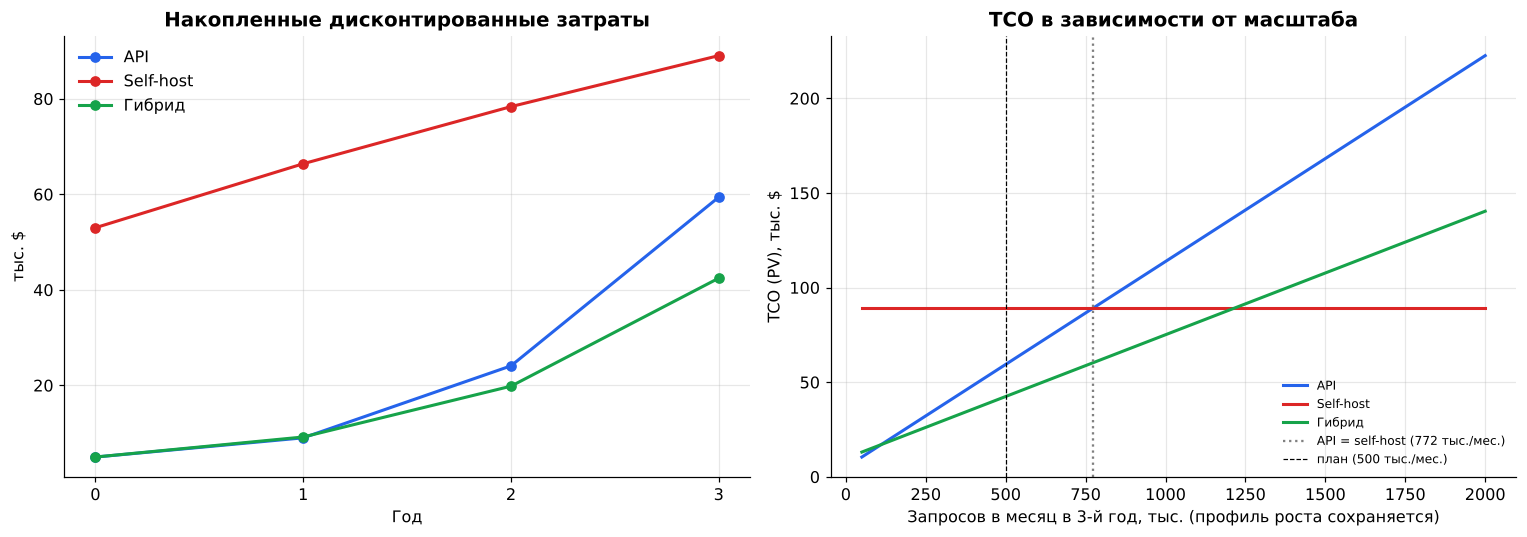

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for v in variants:
    ax.plot(cum.index, cum[v] / 1e3, "o-", lw=2, label=v)
ax.set_xticks(cum.index); ax.set_xlabel("Год"); ax.set_ylabel("тыс. $"); ax.set_title("Накопленные дисконтированные затраты")
ax.legend()
ax = axes[1]
mults = np.linspace(0.1, 4, 80)
for v in variants:
    ax.plot(mults * 500, [pv(v, volume_mult=m) / 1e3 for m in mults], lw=2, label=v)
ax.axvline(m_api * 500, color="gray", ls=":", label=f"API = self-host ({m_api*500:.0f} тыс./мес.)")
ax.axvline(500, color="black", ls="--", lw=0.8, label="план (500 тыс./мес.)")
ax.set_xlabel("Запросов в месяц в 3-й год, тыс. (профиль роста сохраняется)"); ax.set_ylabel("TCO (PV), тыс. $")
ax.set_title("TCO в зависимости от масштаба"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

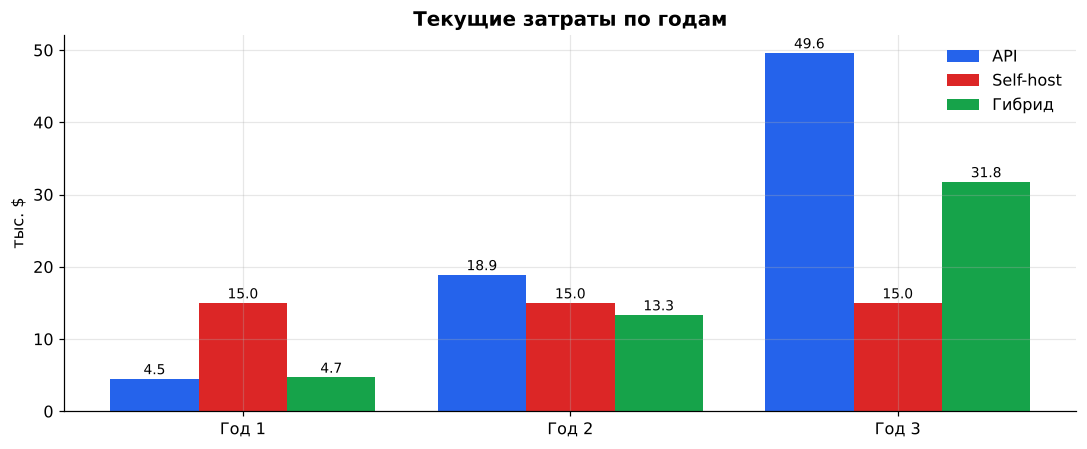

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(H); w = 0.27
for i, v in enumerate(variants):
    b = ax.bar(x + (i - 1) * w, C.loc[1:, v] / 1e3, w, label=v); bar_labels(ax, b, "{:.1f}")
ax.set_xticks(x, [f"Год {t}" for t in range(1, H + 1)]); ax.set_ylabel("тыс. $"); ax.set_title("Текущие затраты по годам")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- Один запрос через API стоит **$0,0075** (около 0,7 руб.), но при 6 млн запросов в 3-й год счёт доходит примерно до $50 тыс. в год.
- **Самая низкая TCO за 3 года у гибрида.** Кеш на 40 % запросов почти вдвое снижает переменные затраты, а стоит всего
  $2 тыс. в год. PV: гибрид около $42 тыс., API около $59 тыс., свой сервер около $89 тыс.
  Свой сервер самый дорогой на 3 годах из-за $53 тыс. разовых вложений.
- **Когда окупается свой сервер.** По текущим расходам он дешевле API уже с 167 тыс. запросов в месяц, это будет во 2-м году.
  Но разовые $53 тыс. окупаются только при большей нагрузке: по TCO за 3 года он сравнивается с API при нагрузке
  в 1,5 раза выше плана (около 770 тыс. запросов в месяц в 3-й год), а с гибридом в 2,4 раза выше (около 1,2 млн).
- **Чувствительность.** Гибрид остаётся лучшим при объёме ±30 %, ценах API ±20 % и доле кеша от 20 до 60 %.
  При +30 % объёма и дорогом API разрыв со своим сервером сокращается. Если же считать объёмы годовыми (в 12 раз меньше),
  API намного дешевле своего сервера, лучший вариант чистый API. То есть решение сильно зависит от реальной нагрузки.

## 7. Выводы и рекомендации

1. **Выбор: гибрид (API + кеширование).** Самая низкая TCO, быстрый запуск, не нужно покупать GPU, качество сильной модели.
2. **Как развивать:** запуск на API, затем кеш типовых вопросов (вопросы граждан часто повторяются, реальная доля кеша
   может быть выше 40 %), а при стабильной нагрузке больше 1 млн запросов в месяц переход на свой сервер с дообученной моделью.
3. **Что отслеживать:** стоимость запроса, долю попаданий в кеш, качество ответов (CSAT, доля передачи оператору),
   объём за месяц и прогноз.

**Риски**
| Риск | Что делать |
|---|---|
| 152-ФЗ и локализация: персональные данные граждан нельзя отправлять в зарубежный API | российский провайдер LLM или свой сервер внутри контура, обезличивание запросов |
| Санкции, зарубежный API или GPU станут недоступны | несколько провайдеров, запасная open-source модель |
| API подорожает | долгий договор, кеширование, простые вопросы отправлять на дешёвые модели |
| Качество open-source модели | дообучение на базе знаний, A/B-тесты, сложные случаи передавать человеку |
| Нагрузка окажется другой | пересчитывать TCO раз в квартал, гибкая архитектура |